# Task 1: ML Classification Project - Customer Churn Prediction
**Run:** Runtime > Run all. No manual download needed: the Telco Customer Churn dataset (IBM sample data, 7,043 customers) is fetched automatically from GitHub (if that ever fails, Colab will prompt you to upload `WA_Fn-UseC_-Telco-Customer-Churn.csv`).

Covers: preprocessing, stratified train/test split, 5-fold cross-validation, two algorithms compared (Logistic Regression, Random Forest), and accuracy / precision / recall / F1 / ROC-AUC.
Outputs (folder `figures/` + files): plots, `task1_metrics.csv`, `Task1_Report.md`, `churn_model.joblib`, `churn_train.csv`, `churn_test.csv`.

In [1]:
import os, warnings, joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings('ignore')
os.makedirs('figures', exist_ok=True)
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve, classification_report)
RS = 42
import os, urllib.request
CSV = 'WA_Fn-UseC_-Telco-Customer-Churn.csv'
URLS = ['https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv',
        'https://raw.githubusercontent.com/treselle-systems/customer_churn_analysis/master/WA_Fn-UseC_-Telco-Customer-Churn.csv']
def get_telco():
    if not os.path.exists(CSV):
        for u in URLS:
            try:
                urllib.request.urlretrieve(u, CSV)
                if pd.read_csv(CSV).shape[0] > 7000: break
            except Exception as e:
                print('download failed:', u, e)
    if not os.path.exists(CSV):                      # last resort: manual upload in Colab
        from google.colab import files; files.upload()
    return pd.read_csv(CSV)


## 1. Load data and explore (EDA)

In [2]:
df = get_telco()
print(df.shape); display(df.head()); print(df.dtypes)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')   # 11 blank strings -> NaN (imputed later)
print('Missing values:\n', df.isna().sum()[df.isna().sum()>0])
df['Churn'] = (df['Churn']=='Yes').astype(int)
print('Churn rate:', df['Churn'].mean().round(4))

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object
Missing values:
 TotalCharges    11
dtype: int64
Churn rate: 0.2654


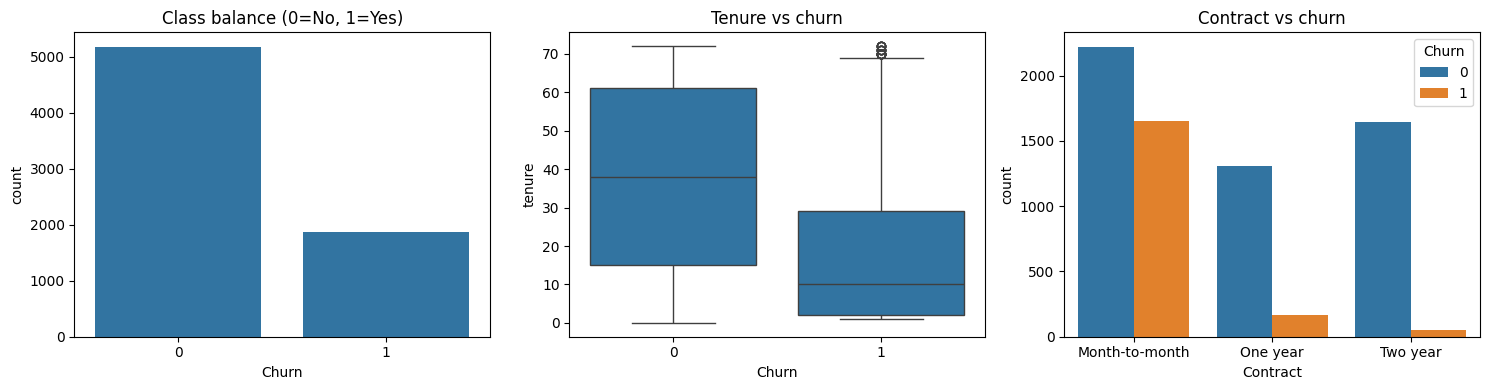

In [3]:
fig, ax = plt.subplots(1,3, figsize=(15,4))
sns.countplot(x='Churn', data=df, ax=ax[0]); ax[0].set_title('Class balance (0=No, 1=Yes)')
sns.boxplot(x='Churn', y='tenure', data=df, ax=ax[1]); ax[1].set_title('Tenure vs churn')
sns.countplot(x='Contract', hue='Churn', data=df, ax=ax[2]); ax[2].set_title('Contract vs churn')
plt.tight_layout(); plt.savefig('figures/eda.png', dpi=200); plt.show()

## 2. Preprocessing pipeline and train/test split
Median imputation + scaling for numeric columns, one-hot encoding for categoricals. The preprocessing sits **inside** the sklearn Pipeline, so it is re-fit on each CV training fold (no leakage). 80/20 stratified split.

In [4]:
X = df.drop(columns=['Churn','customerID']); y = df['Churn']
num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()
pre = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)])
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RS)
print(X_tr.shape, X_te.shape)

(5634, 19) (1409, 19)


## 3. Two algorithms + 5-fold cross-validation + hyper-parameter tuning
GridSearchCV (5-fold stratified, scoring = ROC-AUC) picks the best hyper-parameters for each model; `class_weight='balanced'` handles the ~27% churn imbalance.

In [5]:
models = {
 'Logistic Regression': (Pipeline([('pre',pre),('clf',LogisticRegression(max_iter=1000, class_weight='balanced'))]),
                         {'clf__C':[0.01,0.1,1,10]}),
 'Random Forest': (Pipeline([('pre',pre),('clf',RandomForestClassifier(random_state=RS, class_weight='balanced'))]),
                   {'clf__n_estimators':[200,400],'clf__max_depth':[6,10,None],'clf__min_samples_leaf':[1,5]})}
skf = StratifiedKFold(5, shuffle=True, random_state=RS)
best, cv_rows, best_params = {}, [], {}
for name,(pipe,grid) in models.items():
    gs = GridSearchCV(pipe, grid, cv=skf, scoring='roc_auc', n_jobs=-1).fit(X_tr, y_tr)
    best[name] = gs.best_estimator_; best_params[name] = gs.best_params_
    cv = cross_validate(gs.best_estimator_, X_tr, y_tr, cv=skf, scoring=['accuracy','f1','roc_auc'])
    cv_rows.append([name, cv['test_accuracy'].mean(), cv['test_accuracy'].std(), cv['test_f1'].mean(), cv['test_roc_auc'].mean()])
    print(f'{name}: best params {gs.best_params_} | CV acc {cv["test_accuracy"].mean()*100:.2f} +/- {cv["test_accuracy"].std()*100:.2f} | CV AUC {cv["test_roc_auc"].mean():.4f}')
cv_df = pd.DataFrame(cv_rows, columns=['Model','CV Accuracy','CV Acc std','CV F1','CV ROC-AUC']).set_index('Model').round(4); display(cv_df)

Logistic Regression: best params {'clf__C': 10} | CV acc 74.81 +/- 1.57 | CV AUC 0.8462


Random Forest: best params {'clf__max_depth': 6, 'clf__min_samples_leaf': 5, 'clf__n_estimators': 200} | CV acc 75.03 +/- 1.51 | CV AUC 0.8466


,CV Accuracy,CV Acc std,CV F1,CV ROC-AUC
Model,,,,
Logistic Regression,0.7481,0.0157,0.6275,0.8462
Random Forest,0.7503,0.0151,0.6277,0.8466


## 4. Test-set evaluation (held-out 20%)

In [6]:
rows=[]
for name,m in best.items():
    p = m.predict(X_te); pr = m.predict_proba(X_te)[:,1]
    rows.append([name, accuracy_score(y_te,p), precision_score(y_te,p), recall_score(y_te,p), f1_score(y_te,p), roc_auc_score(y_te,pr)])
res = pd.DataFrame(rows, columns=['Model','Accuracy','Precision','Recall','F1','ROC-AUC']).set_index('Model').round(4)
display(res); res.to_csv('figures/task1_metrics.csv')
for name,m in best.items(): print(name); print(classification_report(y_te, m.predict(X_te)))

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.7395,0.5060,0.7834,0.6149,0.8405
Random Forest,0.7488,0.5174,0.7941,0.6266,0.8419


Logistic Regression
              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1035
           1       0.51      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409

Random Forest
              precision    recall  f1-score   support

           0       0.91      0.73      0.81      1035
           1       0.52      0.79      0.63       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75      0.76      1409



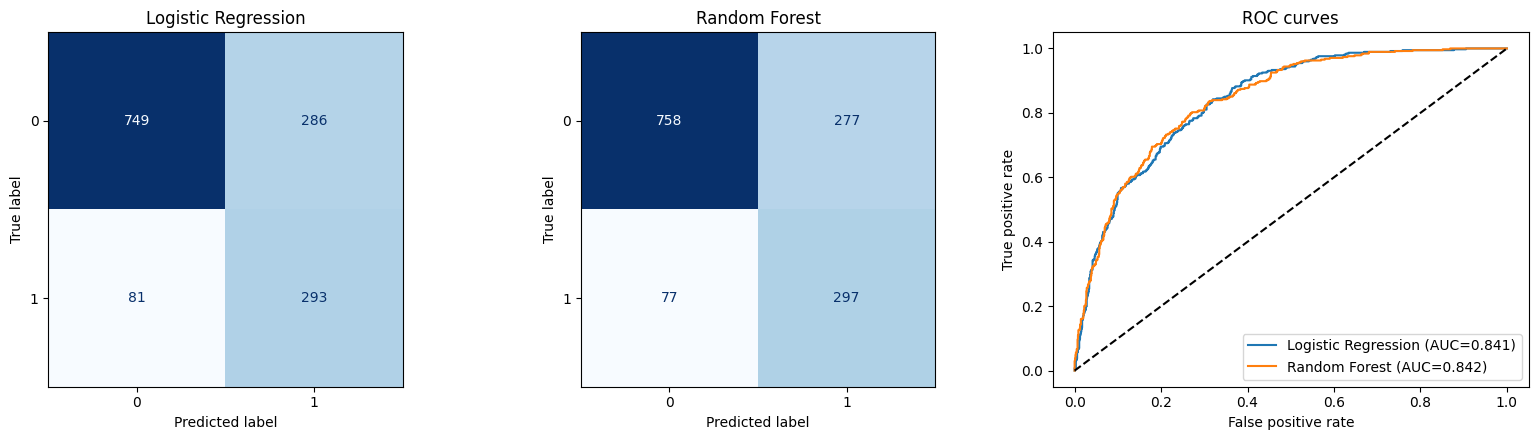

In [7]:
fig, ax = plt.subplots(1,3, figsize=(16,4.5))
for i,(name,m) in enumerate(best.items()):
    ConfusionMatrixDisplay.from_predictions(y_te, m.predict(X_te), ax=ax[i], colorbar=False, cmap='Blues'); ax[i].set_title(name)
for name,m in best.items():
    pr = m.predict_proba(X_te)[:,1]; fpr,tpr,_ = roc_curve(y_te, pr); ax[2].plot(fpr,tpr,label=f"{name} (AUC={roc_auc_score(y_te,pr):.3f})")
ax[2].plot([0,1],[0,1],'k--'); ax[2].set_xlabel('False positive rate'); ax[2].set_ylabel('True positive rate'); ax[2].set_title('ROC curves'); ax[2].legend()
plt.tight_layout(); plt.savefig('figures/task1_cm_roc.png', dpi=200); plt.show()

## 5. Select and save the best model (re-used in Task 3)

In [8]:
final_name = res['ROC-AUC'].idxmax(); print('Selected model:', final_name)
joblib.dump(best[final_name], 'churn_model.joblib')
X_te.assign(Churn=y_te).to_csv('churn_test.csv', index=False)
X_tr.assign(Churn=y_tr).to_csv('churn_train.csv', index=False)

Selected model: Random Forest


## 6. Short report (auto-generated from the results above)

In [9]:
tbl = lambda d: '| Model | ' + ' | '.join(d.columns) + ' |\n|' + '---|'*(len(d.columns)+1) + '\n' + '\n'.join('| '+i+' | '+' | '.join(f'{v:.4f}' for v in r)+' |' for i,r in d.iterrows())
other = [n for n in best if n!=final_name][0]
report = f'''# Task 1 Report: Customer Churn Classification

## Problem and data
Binary classification: predict whether a telecom customer churns. Telco Customer Churn dataset (IBM): {len(df)} customers, {X.shape[1]} features
(demographics, services, contract, billing). Churn rate is {df.Churn.mean()*100:.1f}% (imbalanced). EDA shows churn is concentrated among short-tenure
and month-to-month-contract customers.

## Method
- Preprocessing: `TotalCharges` blanks converted to NaN and median-imputed; numeric features standardised; categoricals one-hot encoded (all inside a Pipeline, so no leakage).
- Split: 80/20 stratified train/test ({len(X_tr)} / {len(X_te)}), random_state=42.
- Models compared: Logistic Regression and Random Forest, both with `class_weight='balanced'`.
- Tuning and validation: GridSearchCV with stratified 5-fold CV (scoring ROC-AUC). Best parameters: {best_params}.

## Results
Cross-validation (training set):

{tbl(cv_df.drop(columns=['CV Acc std']))}

Held-out test set:

{tbl(res)}

## Model selection
**{final_name}** was selected (highest test ROC-AUC: {res.loc[final_name,'ROC-AUC']:.4f} vs {res.loc[other,'ROC-AUC']:.4f} for {other}).
The two models are very close, so the simpler and more interpretable Logistic Regression is a reasonable alternative if explainability matters most.
Because `class_weight='balanced'` was used, recall on churners is high ({res.loc[final_name,'Recall']:.2f}) at the cost of precision ({res.loc[final_name,'Precision']:.2f}):
the model flags most real churners but also some loyal customers. For a retention campaign (cheap offers) this trade-off is usually acceptable;
the decision threshold can be tuned to the real cost of a false alarm versus a lost customer.

## Limitations
Single dataset and single split; no probability calibration; no cost-sensitive threshold tuning. The saved model is audited for bias and explained in Task 3.
'''
open('Task1_Report.md','w').write(report); print(report)

# Task 1 Report: Customer Churn Classification

## Problem and data
Binary classification: predict whether a telecom customer churns. Telco Customer Churn dataset (IBM): 7043 customers, 19 features
(demographics, services, contract, billing). Churn rate is 26.5% (imbalanced). EDA shows churn is concentrated among short-tenure
and month-to-month-contract customers.

## Method
- Preprocessing: `TotalCharges` blanks converted to NaN and median-imputed; numeric features standardised; categoricals one-hot encoded (all inside a Pipeline, so no leakage).
- Split: 80/20 stratified train/test (5634 / 1409), random_state=42.
- Models compared: Logistic Regression and Random Forest, both with `class_weight='balanced'`.
- Tuning and validation: GridSearchCV with stratified 5-fold CV (scoring ROC-AUC). Best parameters: {'Logistic Regression': {'clf__C': 10}, 'Random Forest': {'clf__max_depth': 6, 'clf__min_samples_leaf': 5, 'clf__n_estimators': 200}}.

## Results
Cross-validation (training set):

|

In [10]:
try:
    from google.colab import files
    for f in ['Task1_Report.md','churn_model.joblib','figures/task1_metrics.csv','figures/task1_cm_roc.png','figures/eda.png']: files.download(f)
except ImportError: pass